In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
import os

In [3]:
DATASET_PATH = "/kaggle/input/datasets/emmarex/plantdisease/PlantVillage"

tomato_classes = [folder for folder in os.listdir(DATASET_PATH) if 'Tomato' in folder]


In [4]:
for class_name in sorted(tomato_classes):
    class_path = os.path.join(DATASET_PATH, class_name)

    images = os.listdir(class_path)

    print(f"{class_name}: {len(images)} images")

Tomato_Bacterial_spot: 2127 images
Tomato_Early_blight: 1000 images
Tomato_Late_blight: 1909 images
Tomato_Leaf_Mold: 952 images
Tomato_Septoria_leaf_spot: 1771 images
Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images
Tomato__Target_Spot: 1404 images
Tomato__Tomato_YellowLeaf__Curl_Virus: 3209 images
Tomato__Tomato_mosaic_virus: 373 images
Tomato_healthy: 1591 images


In [5]:
import shutil

TOMATO_PATH = "/kaggle/working/tomato_dataset"

os.makedirs(TOMATO_PATH, exist_ok=True)

for class_name in tomato_classes:
    source = os.path.join(DATASET_PATH, class_name)
    destination = os.path.join(TOMATO_PATH, class_name)

    shutil.copytree(source, destination, dirs_exist_ok=True)

print("Tomato dataset filtering completed!")

Tomato dataset filtering completed!


In [6]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 16

dataset = tf.keras.utils.image_dataset_from_directory(
    'tomato_dataset',
    shuffle=True,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=42
)

class_names = dataset.class_names

n_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", n_classes)

Found 16011 files belonging to 10 classes.
Classes: ['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Number of classes: 10


In [7]:
class_names = dataset.class_names
class_names

['Tomato_Bacterial_spot',
 'Tomato_Early_blight',
 'Tomato_Late_blight',
 'Tomato_Leaf_Mold',
 'Tomato_Septoria_leaf_spot',
 'Tomato_Spider_mites_Two_spotted_spider_mite',
 'Tomato__Target_Spot',
 'Tomato__Tomato_YellowLeaf__Curl_Virus',
 'Tomato__Tomato_mosaic_virus',
 'Tomato_healthy']

In [8]:
len(dataset)

1001

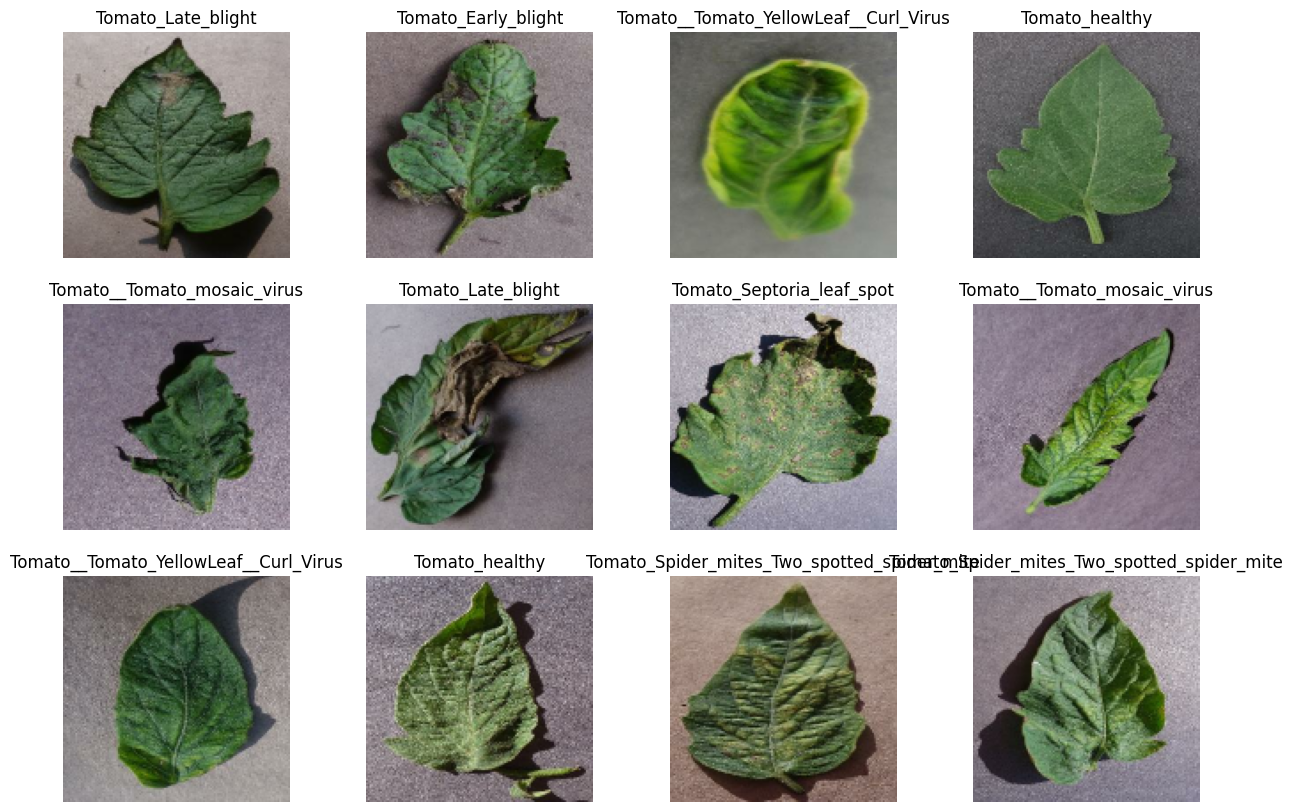

In [9]:
plt.figure(figsize=(15,10))
for image_batch, label_batch in dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i+1)
        plt.imshow(image_batch[i].numpy().astype('uint8'))
        plt.title(class_names[label_batch[i]])
        plt.axis('off')

In [10]:
train_size = 0.8
len(dataset)*train_size

800.8000000000001

In [11]:
train_ds = dataset.take(800)
len(train_ds)

800

In [12]:
def get_dataset_split(ds,train_split=0.8, test_split=0.1, val_split=0.1, shuffle=True, shuffle_size=10000):
    ds_size = len(ds)

    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)
        train_size = int(ds_size * train_split)
        val_size = int(ds_size * val_split)

        train_ds = ds.take(train_size)

        val_ds = ds.skip(train_size).take(val_size)
        test_ds = ds.skip(train_size).skip(val_size)

    return train_ds, val_ds, test_ds


In [13]:
train_ds, val_ds, test_ds = get_dataset_split(dataset)

In [14]:
len(val_ds)

100

In [15]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

In [16]:
resize_rescale = tf.keras.Sequential([
    layers.Resizing(128,128),
    layers.Rescaling(1.0/255)
])

In [17]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.2)
])

In [18]:
batch_size =16
image_size = 128
channels = 3
input_shape = (batch_size, image_size, image_size, channels)

n_classes = len(class_names)

In [23]:
model = models.Sequential([
    resize_rescale,
    data_augmentation,

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(n_classes, activation='softmax')
])

model.build(input_shape=input_shape)

In [24]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (16, 128, 128, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (16, 128, 128, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (16, 126, 126, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (16, 63, 63, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (16, 61, 61, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (16, 30, 30, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (16, 28, 28, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (16, 14, 14, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (16, 128)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (16, 64)               │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (16, 64)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (16, 10)               │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,154 (399.04 KB)

 Trainable params: 102,154 (399.04 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
model.compile(
    optimizer = 'adam',
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics = ['accuracy']
)

In [26]:
history = model.fit(
    train_ds,
    epochs = 50,
    batch_size = batch_size,
    verbose = 1,
    validation_data = val_ds,
    shuffle=False
)

Epoch 1/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 30s 21ms/step - accuracy: 0.3694 - loss: 1.7576 - val_accuracy: 0.5838 - val_loss: 1.2137
Epoch 2/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.5805 - loss: 1.1681 - val_accuracy: 0.6388 - val_loss: 0.9902
Epoch 3/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.6661 - loss: 0.9544 - val_accuracy: 0.7669 - val_loss: 0.6584
Epoch 4/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.7165 - loss: 0.8156 - val_accuracy: 0.7525 - val_loss: 0.6801
Epoch 5/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.7447 - loss: 0.7311 - val_accuracy: 0.8275 - val_loss: 0.4901
Epoch 6/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.7653 - loss: 0.6704 - val_accuracy: 0.8131 - val_loss: 0.5456
Epoch 7/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.7869 - loss: 0.6214 - val_accuracy: 0.8475 - val_loss: 0.4780
Epoch 8/50
800/800 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.7926 - loss: 0.5972 - 

In [27]:
score = model.evaluate(test_ds)
score

101/101 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9728 - loss: 0.0896


[0.08959632366895676, 0.9727723002433777]

In [28]:
history.params

{'verbose': 1, 'epochs': 50, 'steps': 800}

In [29]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

Text(0.5, 1.0, 'Traing and Validattion loss')

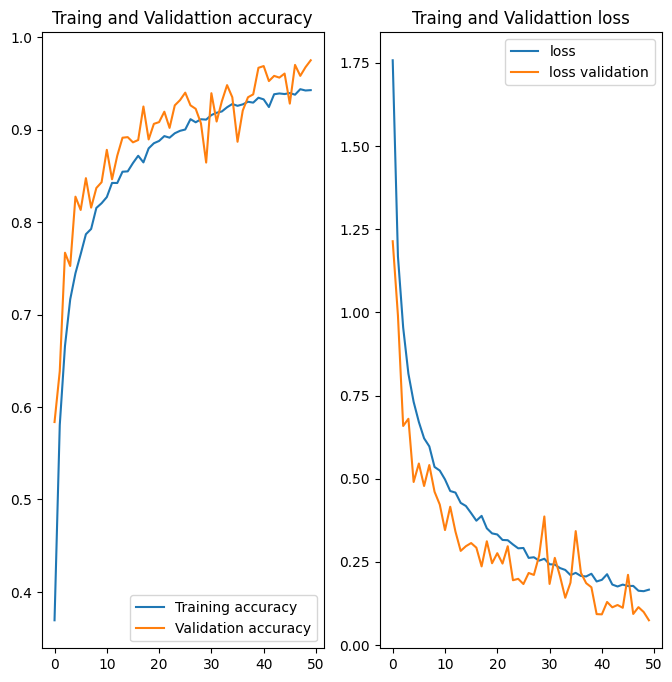

In [30]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8,8))
plt.subplot(1, 2, 1)
plt.plot(range(50), acc, label='Training accuracy')
plt.plot(range(50), val_acc, label='Validation accuracy')
plt.legend()
plt.title('Traing and Validattion accuracy')

plt.subplot(1, 2, 2)
plt.plot(range(50), loss, label='loss')
plt.plot(range(50), val_loss, label='loss validation')
plt.legend()
plt.title('Traing and Validattion loss')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step


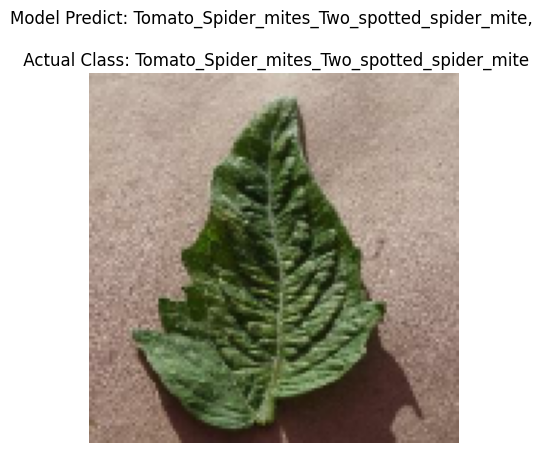

In [32]:
import numpy as np
for image_batch, label_batch in test_ds.take(1):
    
    plt.imshow(image_batch[0].numpy().astype('uint8'))
    actual_class = class_names[label_batch[0]]
    predict = model.predict(image_batch)
    predicted_class = class_names[np.argmax(predict[0])]
    plt.title(f'Model Predict: {predicted_class}, \n\n Actual Class: {actual_class}') 
    plt.axis('off')

In [62]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(image[i].numpy())
    img_array = tf.expand_dims(img_array, 0)
    prediction = model.predict(img_array)
    predict = class_names[np.argmax(prediction[0])]
    confidence = round(100 * (np.max(prediction[0])), 2)
    return predict, confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


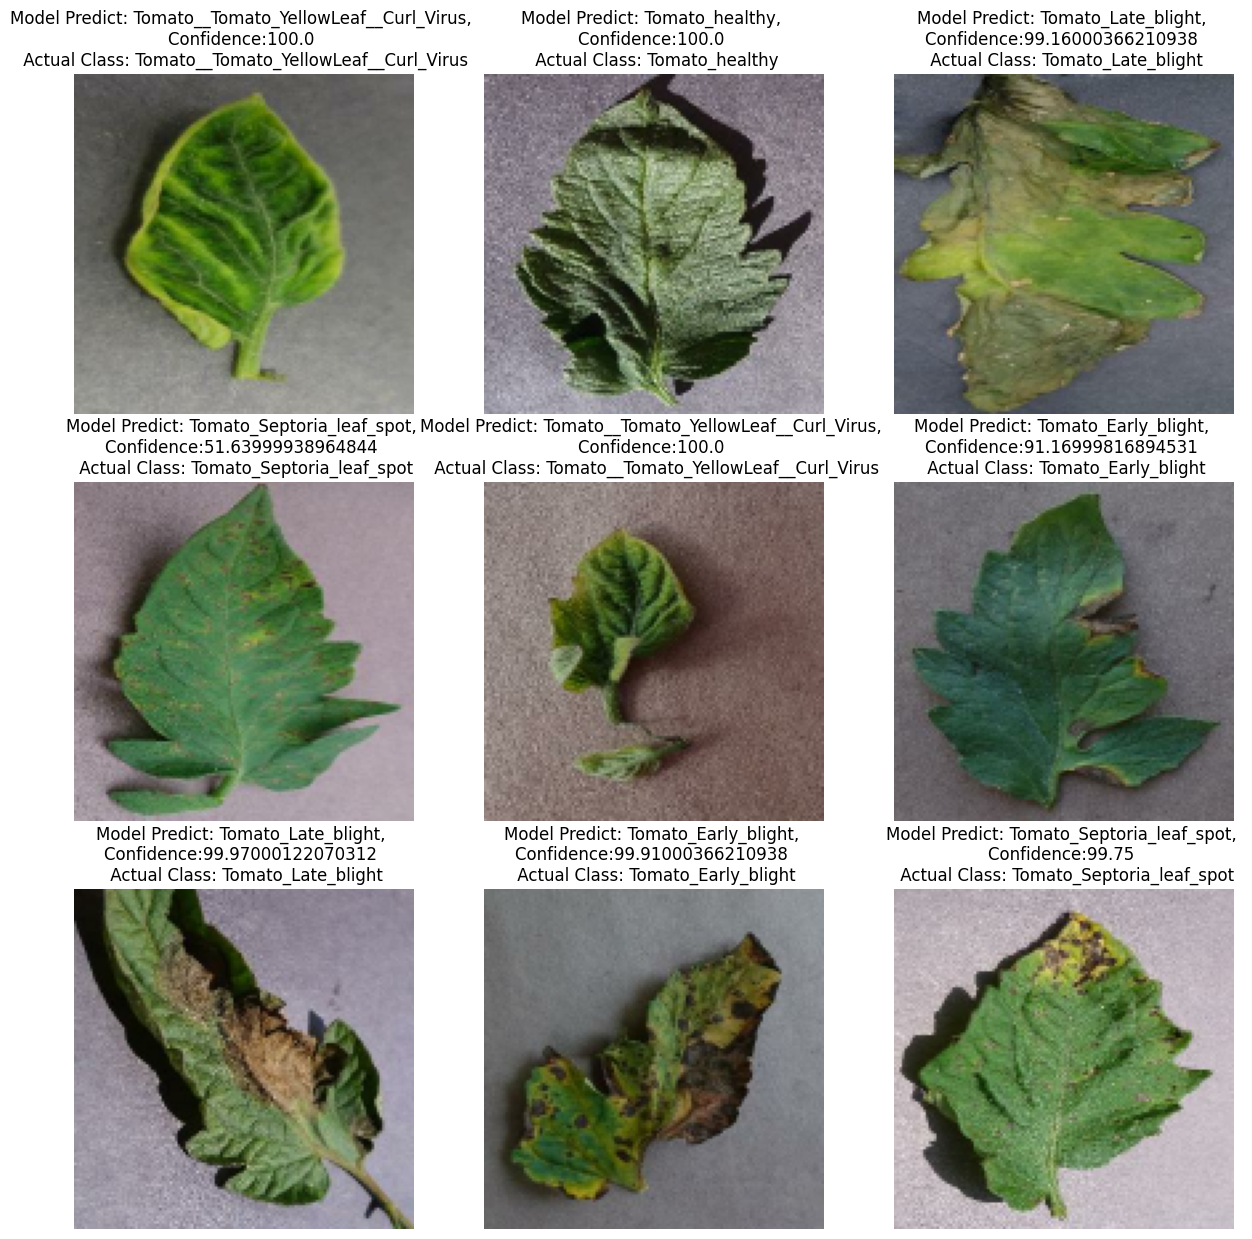

In [71]:
plt.figure(figsize=(15, 15))
for image, label in test_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3,3,i+1)
        plt.imshow(image[i].numpy().astype('uint8'))
        predicted_class, confidence = predict(model, image[i].numpy())

        actual_class = class_names[label[i]]
        plt.title(f'Model Predict: {predicted_class}, \nConfidence:{confidence} \n Actual Class: {actual_class}') 
        plt.axis('off')
        

In [84]:
model_version = 3
model.save(f'model_{model_version}.keras')